In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Зареждане
df = pd.read_csv(
    "data/traffic_aggregated.csv",
    parse_dates=["datetime"]
)

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")
print(f"Период  : {df['datetime'].min()}  →  {df['datetime'].max()}")
print(f"\nNull стойности:")
print(df.isnull().sum().to_string())

Редове  : 52,608
Колони  : ['datetime', 'direction', 'volume', 'avg_speed']
Период  : 2022-01-01 00:00:00  →  2024-12-31 23:00:00

Null стойности:
datetime         0
direction        0
volume       16625
avg_speed    17977


In [2]:
print("=" * 60)
print("ДЕФИНИРАНЕ НА ТЕСТОВИ ПЕРИОДИ")
print("=" * 60)

# Тестови периоди - избираме периоди с непрекъснати данни
# 3 кратки (1-3 дни), 3 средни (1-2 седмици), 3 дълги (1 месец)

test_periods = {
    # Кратки — 3 дни
    "short_1" : ("2023-03-01", "2023-03-03"),
    "short_2" : ("2023-06-01", "2023-06-03"),
    "short_3" : ("2023-11-01", "2023-11-03"),
    # Средни — 2 седмици
    "medium_1": ("2023-03-15", "2023-03-28"),
    "medium_2": ("2023-06-10", "2023-06-23"),
    "medium_3": ("2023-10-15", "2023-10-28"),
    # Дълги — 1 месец
    "long_1"  : ("2023-03-01", "2023-03-31"),
    "long_2"  : ("2023-06-01", "2023-06-30"),
    "long_3"  : ("2023-10-01", "2023-10-31"),
}

# Проверка дали избраните периоди имат данни
print(f"{'Период':<12} {'Начало':<22} {'Край':<22} {'Null volume':>12} {'Общо часа':>10}")
print("-" * 78)

for name, (start, end) in test_periods.items():
    mask = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask]
    null_count = subset["volume"].isnull().sum()
    total = len(subset)
    status = "OK" if null_count == 0 else f"{null_count} null"
    print(f"{name:<12} {start:<22} {end:<22} {status:>12} {total:>10,}")

ДЕФИНИРАНЕ НА ТЕСТОВИ ПЕРИОДИ
Период       Начало                 Край                    Null volume  Общо часа
------------------------------------------------------------------------------
short_1      2023-03-01             2023-03-03                       OK         98
short_2      2023-06-01             2023-06-03                       OK         98
short_3      2023-11-01             2023-11-03                       OK         98
medium_1     2023-03-15             2023-03-28                   2 null        626
medium_2     2023-06-10             2023-06-23                       OK        626
medium_3     2023-10-15             2023-10-28                       OK        626
long_1       2023-03-01             2023-03-31                   2 null      1,442
long_2       2023-06-01             2023-06-30                       OK      1,394
long_3       2023-10-01             2023-10-31                  36 null      1,442


In [3]:
print("=" * 60)
print("НАМИРАНЕ НА ПОДХОДЯЩИ ПЕРИОДИ")
print("=" * 60)

# Проверяваме месеците в 2023 за непрекъснати периоди
months_2023 = {
    "Яну": ("2023-01-01", "2023-01-31"),
    "Фев": ("2023-02-01", "2023-02-28"),
    "Мар": ("2023-03-01", "2023-03-31"),
    "Апр": ("2023-04-01", "2023-04-30"),
    "Май": ("2023-05-01", "2023-05-31"),
    "Юни": ("2023-06-01", "2023-06-30"),
    "Юли": ("2023-07-01", "2023-07-31"),
    "Авг": ("2023-08-01", "2023-08-31"),
    "Сеп": ("2023-09-01", "2023-09-30"),
    "Окт": ("2023-10-01", "2023-10-31"),
    "Ное": ("2023-11-01", "2023-11-30"),
    "Дек": ("2023-12-01", "2023-12-31"),
}

print(f"{'Месец':<8} {'Null volume':>12} {'Общо часа':>10}")
print("-" * 32)
for name, (start, end) in months_2023.items():
    mask = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask]
    null_count = subset["volume"].isnull().sum()
    total = len(subset)
    status = "OK" if null_count == 0 else f"{null_count}"
    print(f"{name:<8} {status:>12} {total:>10,}")

НАМИРАНЕ НА ПОДХОДЯЩИ ПЕРИОДИ
Месец     Null volume  Общо часа
--------------------------------
Яну               938      1,442
Фев               281      1,298
Мар                 2      1,442
Апр                 4      1,394
Май               561      1,442
Юни                OK      1,394
Юли                 5      1,442
Авг                18      1,442
Сеп                28      1,394
Окт                36      1,442
Ное                OK      1,394
Дек                OK      1,442


In [4]:
print("=" * 60)
print("ПРОВЕРКА НА 2022")
print("=" * 60)

months_2022 = {
    "Яну": ("2022-01-01", "2022-01-31"),
    "Фев": ("2022-02-01", "2022-02-28"),
    "Мар": ("2022-03-01", "2022-03-31"),
    "Апр": ("2022-04-01", "2022-04-30"),
    "Май": ("2022-05-01", "2022-05-31"),
    "Юни": ("2022-06-01", "2022-06-30"),
    "Юли": ("2022-07-01", "2022-07-31"),
    "Авг": ("2022-08-01", "2022-08-31"),
    "Сеп": ("2022-09-01", "2022-09-30"),
    "Окт": ("2022-10-01", "2022-10-31"),
    "Ное": ("2022-11-01", "2022-11-30"),
    "Дек": ("2022-12-01", "2022-12-31"),
}

print(f"{'Месец':<8} {'Null volume':>12} {'Общо часа':>10}")
print("-" * 32)
for name, (start, end) in months_2022.items():
    mask = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask]
    null_count = subset["volume"].isnull().sum()
    total = len(subset)
    status = "OK" if null_count == 0 else f"{null_count}"
    print(f"{name:<8} {status:>12} {total:>10,}")

ПРОВЕРКА НА 2022
Месец     Null volume  Общо часа
--------------------------------
Яну               195      1,442
Фев               154      1,298
Мар               619      1,442
Апр               267      1,394
Май               790      1,442
Юни               264      1,394
Юли               899      1,442
Авг               207      1,442
Сеп               103      1,394
Окт              1439      1,442
Ное              1182      1,394
Дек               980      1,442


In [5]:
print("=" * 60)
print("ФИНАЛНИ ТЕСТОВИ ПЕРИОДИ")
print("=" * 60)

# Чисти месеци: Юни 2023, Ноември 2023, Декември 2023
# Избираме периоди от тях

test_periods = {
    # Кратки — 3 дни
    "short_1" : ("2023-06-05", "2023-06-07"),
    "short_2" : ("2023-11-05", "2023-11-07"),
    "short_3" : ("2023-12-05", "2023-12-07"),
    # Средни — 2 седмици
    "medium_1": ("2023-06-05", "2023-06-18"),
    "medium_2": ("2023-11-05", "2023-11-18"),
    "medium_3": ("2023-12-05", "2023-12-18"),
    # Дълги — 1 месец
    "long_1"  : ("2023-06-01", "2023-06-30"),
    "long_2"  : ("2023-11-01", "2023-11-30"),
    "long_3"  : ("2023-12-01", "2023-12-31"),
}

print(f"{'Период':<12} {'Начало':<22} {'Край':<22} {'Null volume':>12} {'Общо часа':>10}")
print("-" * 78)

for name, (start, end) in test_periods.items():
    mask = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask]
    null_count = subset["volume"].isnull().sum()
    total = len(subset)
    status = "OK" if null_count == 0 else f"{null_count} null"
    print(f"{name:<12} {start:<22} {end:<22} {status:>12} {total:>10,}")

ФИНАЛНИ ТЕСТОВИ ПЕРИОДИ
Период       Начало                 Край                    Null volume  Общо часа
------------------------------------------------------------------------------
short_1      2023-06-05             2023-06-07                       OK         98
short_2      2023-11-05             2023-11-07                       OK         98
short_3      2023-12-05             2023-12-07                       OK         98
medium_1     2023-06-05             2023-06-18                       OK        626
medium_2     2023-11-05             2023-11-18                       OK        626
medium_3     2023-12-05             2023-12-18                       OK        626
long_1       2023-06-01             2023-06-30                       OK      1,394
long_2       2023-11-01             2023-11-30                       OK      1,394
long_3       2023-12-01             2023-12-31                       OK      1,442


In [6]:
print("=" * 60)
print("EVALUATION ФУНКЦИИ И СИМУЛАЦИЯ НА GAP-ОВЕ")
print("=" * 60)

from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate(y_true, y_pred, period_name):
    """Изчислява MAE и RMSE за даден период."""
    mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"period": period_name, "MAE": round(mae, 2), "RMSE": round(rmse, 2)}

def create_test_set(df, start, end):
    """
    Извлича период, запазва реалните стойности
    и създава версия с премахнат volume за импутация.
    """
    mask   = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask].copy().reset_index(drop=True)
    # Запазваме реалните стойности
    subset["volume_true"] = subset["volume"]
    # Премахваме volume за симулация на gap
    subset["volume"] = np.nan
    return subset

# Тест — проверяваме че работи
sample = create_test_set(df, "2023-06-05", "2023-06-07")
print(f"Тестов период: {len(sample):,} реда")
print(f"volume_true null : {sample['volume_true'].isnull().sum():,}")
print(f"volume null      : {sample['volume'].isnull().sum():,}")
print(f"\nПример:")
print(sample[["datetime", "direction", "volume", "volume_true"]].head(6).to_string(index=False))

EVALUATION ФУНКЦИИ И СИМУЛАЦИЯ НА GAP-ОВЕ
Тестов период: 98 реда
volume_true null : 0
volume null      : 98

Пример:
           datetime    direction  volume  volume_true
2023-06-05 00:00:00       Център     NaN        149.0
2023-06-05 00:00:00 Околовръстно     NaN        131.0
2023-06-05 01:00:00       Център     NaN         68.0
2023-06-05 01:00:00 Околовръстно     NaN         61.0
2023-06-05 02:00:00       Център     NaN         55.0
2023-06-05 02:00:00 Околовръстно     NaN         32.0


In [7]:
print("=" * 60)
print("METHOD 1: MEAN IMPUTATION")
print("=" * 60)

# Средната стойност по посока от целия dataset (без null)
mean_by_direction = (df.groupby("direction")["volume"]
                     .mean()
                     .round(2))

print("Средна стойност по посока:")
print(mean_by_direction.to_string())

def mean_imputation(test_df, mean_values):
    """Попълва с средната стойност по посока."""
    result = test_df.copy()
    for direction, mean_val in mean_values.items():
        mask = result["direction"] == direction
        result.loc[mask, "volume_imputed"] = mean_val
    return result

# Прилагаме за всички 9 периода
results_mean = []

for name, (start, end) in test_periods.items():
    test  = create_test_set(df, start, end)
    imputed = mean_imputation(test, mean_by_direction)
    score = evaluate(
        imputed["volume_true"].values,
        imputed["volume_imputed"].values,
        name
    )
    score["category"] = name.split("_")[0]
    results_mean.append(score)

results_mean_df = pd.DataFrame(results_mean)
print(f"\nРезултати Mean Imputation:")
print(results_mean_df.to_string(index=False))

print(f"\nСредно по категория:")
print(results_mean_df.groupby("category")[["MAE","RMSE"]]
      .mean().round(2).to_string())

METHOD 1: MEAN IMPUTATION
Средна стойност по посока:
direction
Околовръстно    292.76
Център          331.99

Резултати Mean Imputation:
  period    MAE   RMSE category
 short_1 360.43 411.03    short
 short_2 317.32 376.28    short
 short_3 299.53 330.47    short
medium_1 349.97 406.39   medium
medium_2 369.54 434.74   medium
medium_3 288.49 326.60   medium
  long_1 335.16 389.66     long
  long_2 345.34 405.21     long
  long_3 280.53 319.73     long

Средно по категория:
             MAE    RMSE
category                
long      320.34  371.53
medium    336.00  389.24
short     325.76  372.59


In [8]:
print("=" * 60)
print("METHOD 2: HISTORICAL AVERAGE")
print("=" * 60)

# Изчисляваме средния профил: час x ден от седмицата x посока
# Използваме само данните ИЗВЪН тестовите периоди

def historical_average_imputation(df, test_df, start, end):
    """
    Попълва с историческата средна стойност за
    същия час, ден от седмицата и посока.
    Използва само данни извън тестовия период.
    """
    # Тренировъчни данни — без тестовия период
    train = df[
        (df["datetime"] < start) | (df["datetime"] > end)
    ].copy()

    train["hour"] = train["datetime"].dt.hour
    train["dow"]  = train["datetime"].dt.dayofweek

    # Среден профил по час x dow x посока
    profile = (train.groupby(["dow", "hour", "direction"])["volume"]
               .mean()
               .reset_index()
               .rename(columns={"volume": "volume_imputed"}))

    # Прилагаме към тестовия период
    result = test_df.copy()
    result["hour"] = result["datetime"].dt.hour
    result["dow"]  = result["datetime"].dt.dayofweek

    result = result.merge(profile, on=["dow", "hour", "direction"], how="left")
    result["volume_imputed"] = result["volume_imputed"].round(2)

    return result

# Прилагаме за всички 9 периода
results_hist = []

for name, (start, end) in test_periods.items():
    test    = create_test_set(df, start, end)
    imputed = historical_average_imputation(df, test, start, end)
    score   = evaluate(
        imputed["volume_true"].values,
        imputed["volume_imputed"].values,
        name
    )
    score["category"] = name.split("_")[0]
    results_hist.append(score)

results_hist_df = pd.DataFrame(results_hist)
print(f"Резултати Historical Average:")
print(results_hist_df.to_string(index=False))

print(f"\nСредно по категория:")
print(results_hist_df.groupby("category")[["MAE","RMSE"]]
      .mean().round(2).to_string())

METHOD 2: HISTORICAL AVERAGE
Резултати Historical Average:
  period    MAE   RMSE category
 short_1 233.59 274.02    short
 short_2 213.51 263.89    short
 short_3 132.64 167.65    short
medium_1 230.51 271.75   medium
medium_2 241.33 298.06   medium
medium_3 147.41 181.20   medium
  long_1 220.94 262.69     long
  long_2 215.22 273.40     long
  long_3 143.94 181.37     long

Средно по категория:
             MAE    RMSE
category                
long      193.37  239.15
medium    206.42  250.34
short     193.25  235.19


In [9]:
print("=" * 60)
print("СРАВНЕНИЕ НА СТАТИСТИЧЕСКИТЕ МЕТОДИ")
print("=" * 60)

comparison = pd.DataFrame({
    "period"    : results_mean_df["period"],
    "category"  : results_mean_df["category"],
    "MAE_mean"  : results_mean_df["MAE"],
    "MAE_hist"  : results_hist_df["MAE"],
    "RMSE_mean" : results_mean_df["RMSE"],
    "RMSE_hist" : results_hist_df["RMSE"],
})

comparison["MAE_improvement_%"]  = ((comparison["MAE_mean"] - comparison["MAE_hist"]) 
                                     / comparison["MAE_mean"] * 100).round(1)
comparison["RMSE_improvement_%"] = ((comparison["RMSE_mean"] - comparison["RMSE_hist"]) 
                                     / comparison["RMSE_mean"] * 100).round(1)

print(comparison.to_string(index=False))

print(f"\nСредно подобрение спрямо Mean:")
print(f"  MAE  : -{comparison['MAE_improvement_%'].mean():.1f}%")
print(f"  RMSE : -{comparison['RMSE_improvement_%'].mean():.1f}%")

print(f"\nСредно по категория:")
cat_summary = pd.DataFrame({
    "Mean MAE"  : results_mean_df.groupby("category")["MAE"].mean().round(2),
    "Hist MAE"  : results_hist_df.groupby("category")["MAE"].mean().round(2),
    "Mean RMSE" : results_mean_df.groupby("category")["RMSE"].mean().round(2),
    "Hist RMSE" : results_hist_df.groupby("category")["RMSE"].mean().round(2),
})
print(cat_summary.to_string())

СРАВНЕНИЕ НА СТАТИСТИЧЕСКИТЕ МЕТОДИ
  period category  MAE_mean  MAE_hist  RMSE_mean  RMSE_hist  MAE_improvement_%  RMSE_improvement_%
 short_1    short    360.43    233.59     411.03     274.02               35.2                33.3
 short_2    short    317.32    213.51     376.28     263.89               32.7                29.9
 short_3    short    299.53    132.64     330.47     167.65               55.7                49.3
medium_1   medium    349.97    230.51     406.39     271.75               34.1                33.1
medium_2   medium    369.54    241.33     434.74     298.06               34.7                31.4
medium_3   medium    288.49    147.41     326.60     181.20               48.9                44.5
  long_1     long    335.16    220.94     389.66     262.69               34.1                32.6
  long_2     long    345.34    215.22     405.21     273.40               37.7                32.5
  long_3     long    280.53    143.94     319.73     181.37              

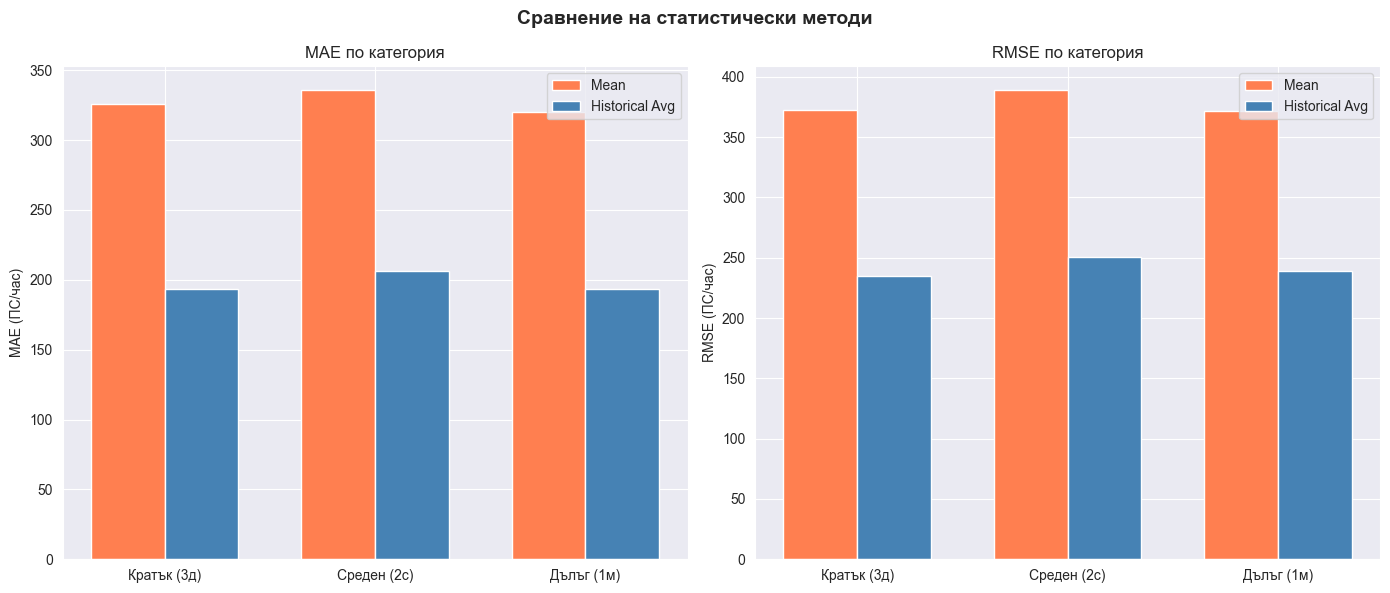

In [10]:
# Визуализация на сравнението
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Сравнение на статистически методи", fontsize=14, fontweight="bold")

categories = ["short", "medium", "long"]
x = np.arange(len(categories))
width = 0.35

# MAE
mean_mae = [results_mean_df[results_mean_df["category"]==c]["MAE"].mean() for c in categories]
hist_mae = [results_hist_df[results_hist_df["category"]==c]["MAE"].mean() for c in categories]

axes[0].bar(x - width/2, mean_mae, width, label="Mean", color="coral", edgecolor="white")
axes[0].bar(x + width/2, hist_mae, width, label="Historical Avg", color="steelblue", edgecolor="white")
axes[0].set_title("MAE по категория")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Кратък (3д)", "Среден (2с)", "Дълъг (1м)"])
axes[0].set_ylabel("MAE (ПС/час)")
axes[0].legend()

# RMSE
mean_rmse = [results_mean_df[results_mean_df["category"]==c]["RMSE"].mean() for c in categories]
hist_rmse = [results_hist_df[results_hist_df["category"]==c]["RMSE"].mean() for c in categories]

axes[1].bar(x - width/2, mean_rmse, width, label="Mean", color="coral", edgecolor="white")
axes[1].bar(x + width/2, hist_rmse, width, label="Historical Avg", color="steelblue", edgecolor="white")
axes[1].set_title("RMSE по категория")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Кратък (3д)", "Среден (2с)", "Дълъг (1м)"])
axes[1].set_ylabel("RMSE (ПС/час)")
axes[1].legend()

plt.tight_layout()
plt.savefig("statistical_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Запазване на статистическите резултати
results_mean_df.to_csv("data/results_mean.csv", index=False)
results_hist_df.to_csv("data/results_hist.csv", index=False)
print("Запазено в data/results_mean.csv")
print("Запазено в data/results_hist.csv")

Запазено в data/results_mean.csv
Запазено в data/results_hist.csv
